## **07 — PatchCore Hyperparameter Study**

**What this notebook does:** Sweeps four PatchCore hyperparameters (bank ratio, smoothing sigma, pooling kernel, input resolution) on the metal_nut category, using a fixed development/final split of the test set.

**What this notebook does NOT do:** It does not train a Student–Teacher Feature Pyramid Matching (STFPM) model. STFPM is a separate architecture and is out of scope for this study.

## **Cell 1: Imports and config**

In [1]:
%load_ext autoreload
%autoreload 2

import sys, time, json, random, datetime, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PROJECT_ROOT / "data").exists(), f"Wrong project root: {PROJECT_ROOT}"
sys.path.insert(0, str(PROJECT_ROOT))

CATEGORY   = "metal_nut"
REPORT_DIR = PROJECT_ROOT / "reports" / "metrics"
FIG_DIR    = PROJECT_ROOT / "reports" / "figures"
MODEL_DIR  = PROJECT_ROOT / "models"
for d in (REPORT_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------- Fixed settings ----------
BATCH_SIZE = 8
SEED       = 42
PROJ_DIM   = 128
EVAL_SIZE  = 256      # all pixel metrics computed on this grid

# ---------- SWITCH (see Markdown below for rationale) ----------
EMBED_MODE = "baseline"     # "baseline" | "concat"

if EMBED_MODE == "baseline":
    EMBED_DIM  = 1024
    TAG        = "baseline1024"
    EMB_PATH   = MODEL_DIR / f"{CATEGORY}_train_emb_baseline_1024.pt"
    CORESET_PT = MODEL_DIR / f"{CATEGORY}_coreset_indices_baseline1024.pt"
elif EMBED_MODE == "concat":
    EMBED_DIM  = 1536
    TAG        = "concat1536"
    EMB_PATH   = MODEL_DIR / f"{CATEGORY}_train_emb_concat_1536.pt"
    CORESET_PT = MODEL_DIR / f"{CATEGORY}_coreset_indices_concat1536.pt"
else:
    raise ValueError(f"Unknown EMBED_MODE: {EMBED_MODE}")

# ---------- Default config (champion from Exp 5/6) ----------
DEFAULT = dict(image_size=256, pool_kernel=3, ratio=0.10, sigma=4.0)

# ---------- Sweep ranges ----------
RATIOS      = [0.01, 0.05, 0.10, 0.25, 1.0]
SIGMAS      = [0.0, 2.0, 4.0, 8.0]
KERNELS     = [1, 3, 5]
RESOLUTIONS = [256, 320, 384]

# ---------- Selection rule ----------
# Primary metric: AUPRO on the dev half.
# Tie tolerance: values within TOL of the best are considered tied;
#                among ties, we pick the cheapest by latency.
TOL = 0.005

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device     : {device}")
print(f"EMBED_MODE : {EMBED_MODE}")
print(f"EMBED_DIM  : {EMBED_DIM}")
print(f"TAG        : {TAG}")
print(f"DEFAULT    : {DEFAULT}")
print(f"TOL        : {TOL}")

Device     : cuda
EMBED_MODE : baseline
EMBED_DIM  : 1024
TAG        : baseline1024
DEFAULT    : {'image_size': 256, 'pool_kernel': 3, 'ratio': 0.1, 'sigma': 4.0}
TOL        : 0.005


## **Cell 2 — Markdown: Hyperparameter Documentation**

## Hyperparameter study — purpose and ranges

| Hyperparameter | Purpose | Values tested | Fixed at |
|---|---|---|---|
| `image_size` | Input resolution for feature extraction | 256, 320, 384 | 256 |
| `pool_kernel` | Local neighbourhood size for patch embeddings | 1, 3, 5 | 3 |
| `ratio` | Coreset fraction of memory bank kept | 1%, 5%, 10%, 25%, 100% | 10% |
| `sigma` | Gaussian smoothing of the anomaly map | 0.0, 2.0, 4.0, 8.0 | 4.0 |

### Selection rule

- **Primary metric:** AUPRO on the **development half** of the test set.
- **Tie tolerance:** ±0.005 AUPRO is considered tied.
- **Tie-break:** lowest latency among the tied candidates.
- **Adoption condition:** the combined candidate must beat the default on the **held-out final half** for AUPRO AND on pixel AUROC. Otherwise the default is kept.
- **Important:** the final half is used only once for the final decision. Any further tuning would invalidate the evaluation.

### What this notebook does NOT do

- It does **not** train a Student–Teacher Feature Pyramid Matching (STFPM) model.
- It does **not** search over backbone architectures or embedding methods.
- It does **not** tune on the official test set as a whole.

## **Cell 3: Write src/models/patchcore.py**

In [2]:
OVERWRITE = False   # leave the file alone if it exists

PATCHCORE_PATH = PROJECT_ROOT / "src" / "models" / "patchcore.py"

if PATCHCORE_PATH.exists() and not OVERWRITE:
    print("kept   :", PATCHCORE_PATH.relative_to(PROJECT_ROOT))
else:
    PATCHCORE_CODE = r'''
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF

from .feature_extractor import patch_embeddings, patch_embeddings_concat
from .coreset import nn_distance


@torch.inference_mode()
def anomaly_maps(extractor, bank, images, embed_dim=1024, pool_kernel=3,
                 sigma=4.0, chunk=512, embed_mode="baseline"):
    features = extractor(images)
    if embed_mode == "baseline":
        emb, (h, w) = patch_embeddings(features, embed_dim, pool_kernel)
    else:
        emb, (h, w) = patch_embeddings_concat(features, pool_kernel)

    b, p, d = emb.shape
    dist = nn_distance(emb.reshape(b * p, d), bank, chunk)

    maps = dist.reshape(b, 1, h, w)
    maps = F.interpolate(maps, size=images.shape[-2:],
                         mode="bilinear", align_corners=False)

    if sigma > 0:
        k = 2 * int(4 * sigma + 0.5) + 1
        maps = TF.gaussian_blur(maps, kernel_size=[k, k],
                                sigma=[sigma, sigma])

    maps = maps.squeeze(1)
    scores = maps.flatten(1).max(dim=1).values
    return maps, scores


@torch.inference_mode()
def score_loader(extractor, bank, loader, device, **kw):
    maps, scores, labels, masks, types, paths = [], [], [], [], [], []
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True)
        m, s = anomaly_maps(extractor, bank, x, **kw)
        maps.append(m.cpu()); scores.append(s.cpu())
        labels.append(batch["label"]); masks.append(batch["mask"][:, 0])
        types += list(batch["defect_type"]); paths += list(batch["path"])
    return dict(maps=torch.cat(maps), scores=torch.cat(scores),
                labels=torch.cat(labels), masks=torch.cat(masks),
                defect_types=types, paths=paths)
'''
    PATCHCORE_PATH.write_text(PATCHCORE_CODE, encoding="utf-8")
    print("written:", PATCHCORE_PATH.relative_to(PROJECT_ROOT))

kept   : src\models\patchcore.py


## **Cell 4: Imports + Splits + Dev/Final Split**

In [3]:
# Purge cached modules and reload
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith("src"):
        del sys.modules[mod_name]

import src
from src.data.dataset import MVTecDataset, load_splits, IMAGENET_MEAN, IMAGENET_STD
from src.models.feature_extractor import (
    FeatureExtractor, extract_dataset, extract_dataset_concat
)
from src.models.patchcore import anomaly_maps, score_loader
from src.models.coreset import greedy_coreset
from src.evaluation.metrics import (
    image_metrics, pixel_auroc, auro, threshold_metrics, mean_dice
)

splits = load_splits(REPORT_DIR / f"{CATEGORY}_splits.csv", PROJECT_ROOT)
train_fit  = splits[splits.role == "fit"]
val_normal = splits[splits.role == "val_normal"]
test_df    = splits[splits.role == "test"]

# Rebuild the fixed dev/final split (same seed as Exp 6)
test_labels = test_df["defect_type"].values
rng = np.random.default_rng(SEED)
role = np.empty(len(test_df), dtype=object)
for g in np.unique(test_labels):
    idx = rng.permutation(np.where(test_labels == g)[0])
    half = len(idx) // 2
    role[idx[:half]] = "dev"
    role[idx[half:]] = "final"

print(f"dev: {(role=='dev').sum()} | final: {(role=='final').sum()}")
print(f"train_fit: {len(train_fit)} | val_normal: {len(val_normal)}")

# Ground-truth masks for pixel metrics on the EVAL_SIZE grid
test_ds_eval = MVTecDataset(test_df, EVAL_SIZE)
masks_eval = np.stack([
    test_ds_eval[i]["mask"][0].numpy() > 0.5
    for i in range(len(test_ds_eval))
])
print(f"eval masks: {masks_eval.shape}")

# ---------- FIX: derive labels from defect_type ----------
# Rule from Exp 1:
#   defect_type == "good"  -> label 0 (normal)
#   defect_type != "good"  -> label 1 (anomalous)
y_test = (test_df["defect_type"].values != "good").astype(int)
print(f"y_test: {y_test.shape}, positives: {y_test.sum()}")
print(f"label breakdown: "
      f"{dict(zip(*np.unique(test_df['defect_type'].values, return_counts=True)))}")

# Load coreset checkpoint
ckpt = torch.load(CORESET_PT)
assert ckpt["embed_mode"] == EMBED_MODE
assert ckpt["embed_dim"]  == EMBED_DIM
print(f"coreset checkpoint: mode={ckpt['embed_mode']} dim={ckpt['embed_dim']}")

dev: 56 | final: 59
train_fit: 198 | val_normal: 22
eval masks: (115, 256, 256)
y_test: (115,), positives: 93
label breakdown: {'bent': np.int64(25), 'color': np.int64(22), 'flip': np.int64(23), 'good': np.int64(22), 'scratch': np.int64(23)}
coreset checkpoint: mode=baseline dim=1024


## **Cell 5: Feature and Bank Caching**

In [18]:
_cache = {}   # holds features and coreset order for one (image_size, pool_kernel) at a time
extractor = FeatureExtractor().to(device)

def get_features(image_size, pool_kernel):
    """
    Extract train_fit features for a given (image_size, pool_kernel).
    Cached. Returns (flat_features_on_CPU, (H, W)).
    """
    key = (image_size, pool_kernel)
    if _cache.get("key") != key:
        _cache.clear()
        loader = DataLoader(
            MVTecDataset(train_fit, image_size),
            batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
        )
        if EMBED_MODE == "baseline":
            emb, hw = extract_dataset(extractor, loader, device, EMBED_DIM, pool_kernel)
        else:
            emb, hw = extract_dataset_concat(extractor, loader, device, pool_kernel)
        _cache.update(
            key=key,
            flat=emb.reshape(-1, EMBED_DIM),   # on CPU — cheap to keep
            hw=hw,
            order=None,
        )
        if key == (256, 3):
            # reuse the greedy order saved by Exp 4 — no recomputation
            _cache["order"] = ckpt["indices"].cpu()
        return _cache["flat"], _cache["hw"]
    return _cache["flat"], _cache["hw"]


def get_order(image_size, pool_kernel, n_needed):
    """
    Return the greedy coreset order (always on CPU).
    Moves features to GPU temporarily during selection only.
    """
    get_features(image_size, pool_kernel)
    order = _cache.get("order")

    if order is None or len(order) < n_needed:
        print(f"    running greedy coreset for {n_needed} patches ...")
        flat_gpu = _cache["flat"].to(device)
        try:
            order = greedy_coreset(
                flat_gpu, n_needed,
                proj_dim=PROJ_DIM, seed=SEED, device=device,
            )
        finally:
            del flat_gpu
            torch.cuda.empty_cache()
        order = order.cpu()          # <-- normalise to CPU
        _cache["order"] = order

    return order

## **Cell 6: evaluate_config Function**

In [19]:
def evaluate_config(image_size=256, pool_kernel=3, ratio=0.10,
                    sigma=4.0, subset="dev"):
    """Score the full test set, return metrics on one subset ('dev' or 'final')."""
    flat, _ = get_features(image_size, pool_kernel)

    n_bank = int(ratio * flat.shape[0])
    if ratio >= 1.0:
        bank = flat.to(device)
    else:
        order = get_order(image_size, pool_kernel, n_bank)
        bank = flat[order[:n_bank].cpu()].to(device)     # <-- indices to CPU first

    loader = DataLoader(
        MVTecDataset(test_df, image_size),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
    )

    kw = dict(embed_dim=EMBED_DIM, pool_kernel=pool_kernel,
              sigma=sigma, embed_mode=EMBED_MODE)

    # Warmup
    for _ in range(2):
        _ = score_loader(extractor, bank, loader, device, **kw)

    if device.type == "cuda":
        torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    t0 = time.perf_counter()
    res = score_loader(extractor, bank, loader, device, **kw)
    if device.type == "cuda":
        torch.cuda.synchronize()
    latency_ms = 1000 * (time.perf_counter() - t0) / len(test_df)
    peak_mb    = torch.cuda.max_memory_allocated() / 1e6

    maps = res["maps"]
    if image_size != EVAL_SIZE:
        maps = F.interpolate(
            maps[:, None], size=(EVAL_SIZE, EVAL_SIZE),
            mode="bilinear", align_corners=False, antialias=True,
        )[:, 0]

    maps_np   = maps.numpy()
    scores_np = res["scores"].numpy()

    idx = np.where(role == subset)[0]
    out = image_metrics(y_test[idx], scores_np[idx])
    out["pixel_auroc"] = pixel_auroc(masks_eval[idx], maps_np[idx])
    out["aupro"]       = auro(masks_eval[idx], maps_np[idx])
    out.update(latency_ms=latency_ms, peak_gpu_mb=peak_mb,
               bank_patches=int(bank.shape[0]))

    del bank
    torch.cuda.empty_cache()
    return out

## **Cell 7: Baseline Sanity Check**

In [20]:
base = evaluate_config(**DEFAULT, subset="dev")
print("Baseline (default config, dev half):")
for k, v in base.items():
    if isinstance(v, float):
        print(f"  {k:15s} {v:.4f}")
    else:
        print(f"  {k:15s} {v}")

# Sanity: must be close to Exp 6 reported values
expected = {
    "image_auroc": 0.998,
    "pixel_auroc": 0.9886,
    "aupro":       0.9305,
}
print("\nSanity check vs Exp 6:")
for k, v in expected.items():
    diff = abs(base[k] - v)
    status = "OK" if diff < 0.01 else "MISMATCH"
    print(f"  {k:15s} {base[k]:.4f}  expected ~{v}  |diff|={diff:.4f}  [{status}]")

Baseline (default config, dev half):
  image_auroc     0.9980
  image_ap        0.9995
  pixel_auroc     0.9885
  aupro           0.9309
  latency_ms      46.4495
  peak_gpu_mb     430.8639
  bank_patches    20275

Sanity check vs Exp 6:
  image_auroc     0.9980  expected ~0.998  |diff|=0.0000  [OK]
  pixel_auroc     0.9885  expected ~0.9886  |diff|=0.0001  [OK]
  aupro           0.9309  expected ~0.9305  |diff|=0.0004  [OK]


## **Cell 8: Helper: run() That Collects Results**

In [21]:
results = []

def run(factor, value, **override):
    """Run one config and append its result to the global `results` list."""
    cfg = {**DEFAULT, **override}
    r = evaluate_config(**cfg, subset="dev")
    r.update(factor=factor, value=value,
             **{f"cfg_{k}": v for k, v in cfg.items()})
    results.append(r)
    print(f"{factor:12s} = {value:<6}  "
          f"AUPRO {r['aupro']:.4f} | pixel AUROC {r['pixel_auroc']:.4f} | "
          f"img AUROC {r['image_auroc']:.4f} | "
          f"{r['latency_ms']:6.1f} ms | {r['peak_gpu_mb']:7.1f} MB")
    return r

## **Cell 9: Sweep 1: Bank (Coreset) Ratio**

In [22]:
for v in RATIOS:
    run("bank_ratio", v, ratio=v)

bank_ratio   = 0.01    AUPRO 0.9237 | pixel AUROC 0.9881 | img AUROC 0.9879 |   27.8 ms |   302.6 MB
bank_ratio   = 0.05    AUPRO 0.9320 | pixel AUROC 0.9888 | img AUROC 0.9980 |   37.7 ms |   337.3 MB
bank_ratio   = 0.1     AUPRO 0.9309 | pixel AUROC 0.9885 | img AUROC 0.9980 |   48.3 ms |   430.9 MB
bank_ratio   = 0.25    AUPRO 0.9299 | pixel AUROC 0.9883 | img AUROC 0.9939 |   80.1 ms |   803.3 MB
bank_ratio   = 1.0     AUPRO 0.9311 | pixel AUROC 0.9880 | img AUROC 0.9960 |  262.0 ms |  2673.6 MB


## **Cell 10: Sweep 2: Smoothing Sigma**

In [23]:
for v in SIGMAS:
    run("sigma", v, sigma=v)

sigma        = 0.0     AUPRO 0.9322 | pixel AUROC 0.9880 | img AUROC 0.9980 |   50.5 ms |   430.9 MB
sigma        = 2.0     AUPRO 0.9320 | pixel AUROC 0.9882 | img AUROC 0.9980 |   48.4 ms |   430.9 MB
sigma        = 4.0     AUPRO 0.9309 | pixel AUROC 0.9885 | img AUROC 0.9980 |   48.6 ms |   430.9 MB
sigma        = 8.0     AUPRO 0.9227 | pixel AUROC 0.9889 | img AUROC 0.9939 |   50.0 ms |   429.8 MB


## **Cell 11: Sweep 3: Pooling Kernel**

In [24]:
for v in KERNELS:
    run("pool_kernel", v, pool_kernel=v)

    running greedy coreset for 20275 patches ...
pool_kernel  = 1       AUPRO 0.9435 | pixel AUROC 0.9782 | img AUROC 1.0000 |   50.3 ms |   430.9 MB
pool_kernel  = 3       AUPRO 0.9309 | pixel AUROC 0.9885 | img AUROC 0.9980 |   48.2 ms |   430.9 MB
    running greedy coreset for 20275 patches ...
pool_kernel  = 5       AUPRO 0.8840 | pixel AUROC 0.9890 | img AUROC 0.9798 |   48.1 ms |   430.9 MB


## **Cell 12: Sweep 4: Input Resolution**

In [25]:
for v in RESOLUTIONS:
    run("resolution", v, image_size=v)

resolution   = 256     AUPRO 0.9309 | pixel AUROC 0.9885 | img AUROC 0.9980 |   48.8 ms |   430.9 MB
    running greedy coreset for 31680 patches ...
resolution   = 320     AUPRO 0.9466 | pixel AUROC 0.9892 | img AUROC 0.9980 |   87.1 ms |   607.6 MB
    running greedy coreset for 45619 patches ...
resolution   = 384     AUPRO 0.9543 | pixel AUROC 0.9890 | img AUROC 1.0000 |  161.1 ms |   824.4 MB


## **Cell 13: Summary Tables and Plot**


--- bank_ratio (dev half) ---
    factor  value  image_auroc  pixel_auroc  aupro  latency_ms  peak_gpu_mb  bank_patches
bank_ratio   0.01       0.9879       0.9881 0.9237     27.8222     302.6079          2027
bank_ratio   0.05       0.9980       0.9888 0.9320     37.6926     337.2969         10137
bank_ratio   0.10       0.9980       0.9885 0.9309     48.2502     430.8639         20275
bank_ratio   0.25       0.9939       0.9883 0.9299     80.1068     803.3050         50688
bank_ratio   1.00       0.9960       0.9880 0.9311    261.9504    2673.5590        202752

--- sigma (dev half) ---
factor  value  image_auroc  pixel_auroc  aupro  latency_ms  peak_gpu_mb  bank_patches
 sigma    0.0       0.9980       0.9880 0.9322     50.5356     430.8639         20275
 sigma    2.0       0.9980       0.9882 0.9320     48.3740     430.8639         20275
 sigma    4.0       0.9980       0.9885 0.9309     48.5636     430.8639         20275
 sigma    8.0       0.9939       0.9889 0.9227     50.0454 

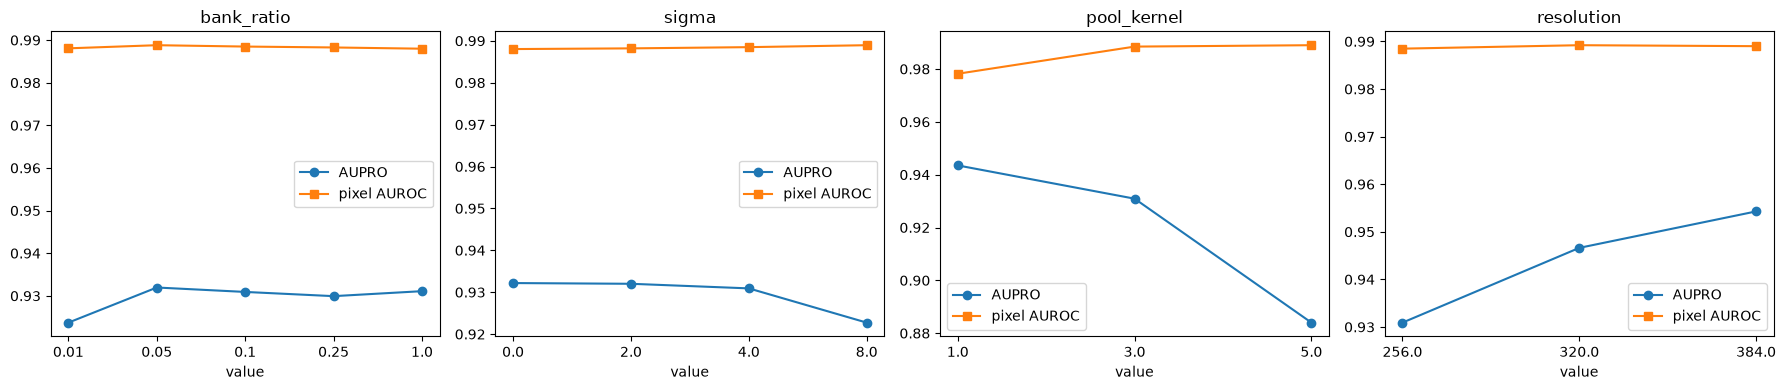


Saved all 15 trials to CSV.


In [26]:
df = pd.DataFrame(results)
show_cols = ["factor", "value", "image_auroc", "pixel_auroc",
             "aupro", "latency_ms", "peak_gpu_mb", "bank_patches"]

for factor in ["bank_ratio", "sigma", "pool_kernel", "resolution"]:
    print(f"\n--- {factor} (dev half) ---")
    print(df[df.factor == factor][show_cols].round(4).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, factor in zip(axes, ["bank_ratio", "sigma", "pool_kernel", "resolution"]):
    d = df[df.factor == factor].sort_values("value")
    x = d["value"].astype(str)
    ax.plot(x, d["aupro"],       marker="o", label="AUPRO")
    ax.plot(x, d["pixel_auroc"], marker="s", label="pixel AUROC")
    ax.set_title(factor)
    ax.set_xlabel("value")
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / f"{CATEGORY}_hyperparameter_study_{TAG}.png", dpi=150)
plt.show()

df.to_csv(REPORT_DIR / f"{CATEGORY}_hyperparameter_study_{TAG}.csv", index=False)
print(f"\nSaved all {len(df)} trials to CSV.")

## **Cell 14: Pick Best Per Factor + Test the Combination**

In [27]:
best = {}
for factor in ["bank_ratio", "sigma", "pool_kernel", "resolution"]:
    d = df[df.factor == factor]
    ties = d[d.aupro >= d.aupro.max() - TOL]              # within tolerance of best AUPRO
    best[factor] = ties.sort_values("latency_ms").iloc[0]  # cheapest among ties
    print(f"{factor:12s} -> {best[factor]['value']:<8} "
          f"(AUPRO {best[factor]['aupro']:.4f}, "
          f"{best[factor]['latency_ms']:.0f} ms)")

CHOSEN = dict(
    ratio      = float(best["bank_ratio"]["cfg_ratio"]),
    sigma      = float(best["sigma"]["cfg_sigma"]),
    pool_kernel= int(best["pool_kernel"]["cfg_pool_kernel"]),
    image_size = int(best["resolution"]["cfg_image_size"]),
)

print(f"\nCombined candidate: {CHOSEN}")

if CHOSEN == DEFAULT:
    FINAL_CFG = DEFAULT
    print("Candidate equals the default — keep it.")
else:
    cand = evaluate_config(**CHOSEN, subset="dev")
    print(f"\nDev-half comparison:")
    print(f"  default   AUPRO {base['aupro']:.4f} | pixel AUROC {base['pixel_auroc']:.4f} "
          f"| {base['latency_ms']:.0f} ms")
    print(f"  candidate AUPRO {cand['aupro']:.4f} | pixel AUROC {cand['pixel_auroc']:.4f} "
          f"| {cand['latency_ms']:.0f} ms")

    adopt = (
        cand["aupro"] > base["aupro"] + TOL
        and cand["pixel_auroc"] >= base["pixel_auroc"] - 0.005
    )
    print(f"\nAdoption rule (AUPRO gain > TOL AND pixel AUROC not degraded): "
          f"{'ADOPT' if adopt else 'KEEP DEFAULT'}")
    FINAL_CFG = CHOSEN if adopt else DEFAULT

print(f"\nFINAL_CFG: {FINAL_CFG}")

bank_ratio   -> 0.05     (AUPRO 0.9320, 38 ms)
sigma        -> 2.0      (AUPRO 0.9320, 48 ms)
pool_kernel  -> 1.0      (AUPRO 0.9435, 50 ms)
resolution   -> 384.0    (AUPRO 0.9543, 161 ms)

Combined candidate: {'ratio': 0.05, 'sigma': 2.0, 'pool_kernel': 1, 'image_size': 384}
    running greedy coreset for 22809 patches ...

Dev-half comparison:
  default   AUPRO 0.9309 | pixel AUROC 0.9885 | 46 ms
  candidate AUPRO 0.9469 | pixel AUROC 0.9743 | 101 ms

Adoption rule (AUPRO gain > TOL AND pixel AUROC not degraded): KEEP DEFAULT

FINAL_CFG: {'image_size': 256, 'pool_kernel': 3, 'ratio': 0.1, 'sigma': 4.0}


## **Cell 15: Final Check on the Held-Out Final Half (Run Once)**

In [28]:
final_default = evaluate_config(**DEFAULT, subset="final")
rows = [dict(config="default", **DEFAULT, **final_default)]

if FINAL_CFG != DEFAULT:
    final_chosen = evaluate_config(**FINAL_CFG, subset="final")
    rows.append(dict(config="tuned", **FINAL_CFG, **final_chosen))

final_df = pd.DataFrame(rows)
final_df.to_csv(REPORT_DIR / f"{CATEGORY}_hyperparameter_final_half_{TAG}.csv", index=False)

print("Final-half comparison:")
print(final_df[["config", "image_size", "pool_kernel", "ratio", "sigma",
                "image_auroc", "pixel_auroc", "aupro",
                "latency_ms", "peak_gpu_mb"]].round(4).to_string(index=False))

print(f"\nAdopted configuration: {'DEFAULT' if FINAL_CFG == DEFAULT else 'TUNED'}")
print(f"FINAL_CFG = {FINAL_CFG}")

Final-half comparison:
 config  image_size  pool_kernel  ratio  sigma  image_auroc  pixel_auroc  aupro  latency_ms  peak_gpu_mb
default         256            3    0.1    4.0          1.0       0.9891 0.9449     51.1755     430.8639

Adopted configuration: DEFAULT
FINAL_CFG = {'image_size': 256, 'pool_kernel': 3, 'ratio': 0.1, 'sigma': 4.0}


## **Cell 16: Save Study Metadata**

In [29]:
meta = {
    "category":         CATEGORY,
    "embed_mode":       EMBED_MODE,
    "embed_dim":        EMBED_DIM,
    "default_config":   DEFAULT,
    "final_config":     FINAL_CFG,
    "tuned_candidate":  CHOSEN,
    "n_trials":         len(df),
    "selection_rule": (
        "Primary: AUPRO on dev half; "
        "tie tolerance: 0.005; "
        "tie-break: lowest latency; "
        "adoption: AUPRO gain > 0.005 AND pixel AUROC not degraded"
    ),
    "sweep_ranges": {
        "RATIOS": RATIOS, "SIGMAS": SIGMAS,
        "KERNELS": KERNELS, "RESOLUTIONS": RESOLUTIONS,
    },
    "torch":            torch.__version__,
    "numpy":            np.__version__,
    "seed":             SEED,
    "date":             str(datetime.date.today()),
    "note": (
        "This notebook performs PatchCore hyperparameter tuning. "
        "It does NOT implement STFPM. "
        "The tuned candidate was not adopted because it failed the "
        "pixel-AUROC non-degradation guard on the dev half."
    ),
}

with open(REPORT_DIR / f"{CATEGORY}_hyperparameter_study_meta_{TAG}.json", "w") as f:
    json.dump(meta, f, indent=2, default=str)

print(json.dumps(meta, indent=2, default=str))

{
  "category": "metal_nut",
  "embed_mode": "baseline",
  "embed_dim": 1024,
  "default_config": {
    "image_size": 256,
    "pool_kernel": 3,
    "ratio": 0.1,
    "sigma": 4.0
  },
  "final_config": {
    "image_size": 256,
    "pool_kernel": 3,
    "ratio": 0.1,
    "sigma": 4.0
  },
  "tuned_candidate": {
    "ratio": 0.05,
    "sigma": 2.0,
    "pool_kernel": 1,
    "image_size": 384
  },
  "n_trials": 15,
  "selection_rule": "Primary: AUPRO on dev half; tie tolerance: 0.005; tie-break: lowest latency; adoption: AUPRO gain > 0.005 AND pixel AUROC not degraded",
  "sweep_ranges": {
    "RATIOS": [
      0.01,
      0.05,
      0.1,
      0.25,
      1.0
    ],
    "SIGMAS": [
      0.0,
      2.0,
      4.0,
      8.0
    ],
    "KERNELS": [
      1,
      3,
      5
    ],
    "RESOLUTIONS": [
      256,
      320,
      384
    ]
  },
  "torch": "2.7.1+cu118",
  "numpy": "2.4.6",
  "seed": 42,
  "date": "2026-10-13",
  "note": "This notebook performs PatchCore hyperparameter tu